In [1]:
!pip install roboflow
!pip install ultralytics
!pip install pytorch_lightning
!pip install torchvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 381.4/381.4 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 80.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 51.5 MB/s eta 0:00:00


In [2]:
import torch

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    print("GPU not available")
    device = torch.device("cpu")

In [3]:
from google.colab import userdata
from roboflow import Roboflow
import os
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import cv2
from getpass import getpass
from ultralytics import YOLO
import pytorch_lightning as pl
from torchvision.models.detection.faster_rcnn import FasterRCNN
from torchvision.models.detection.rpn import AnchorGenerator
from torchvision.ops import MultiScaleRoIAlign

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [6]:
api_key = userdata.get("ROBOFLOW_API_KEY") #for Google colab UI
workspace_slug = userdata.get('ROBOFLOW_WORKSPACE')
cell_slug = userdata.get('ROBOFLOW_PROJECT_CELL')
blood_slug = userdata.get('ROBOFLOW_PROJECT_BLOOD')



In [7]:
rf = Roboflow(api_key=api_key) # *---- Add api key to secrect w name ROBOFLOW_API_KEY ----*
project = project = rf.workspace(workspace_slug).project(cell_slug)  # *-------- Need to change this to specific dir --------*
version = project.version(2) #version generated on roboflow universe
cell_yolo_dataset = version.download(
                                model_format="yolo26",
                                location = "./cell_detection/yolo26",
                                overwrite=True) #chose this format for PyTorch compatibality


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to ./cell_detection/yolo26 in yolo26:: 100%|██████████| 1004/1004 [00:00<00:00, 8520.42it/s]


In [10]:
print(os.listdir(cell_yolo_dataset.location))
assert "data.yaml" in os.listdir(cell_yolo_dataset.location), "Incorrect data format, download as yolo"

['valid', 'train', 'README.roboflow.txt', 'data.yaml', 'test']


In [12]:
import time
timestamp = time.time()

model = YOLO("yolo26n.pt")
results = model.train(data=f"{cell_yolo_dataset.location}/data.yaml",
                      epochs=100,
                      imgsz=640,
                      single_cls=True,
                      project="./cell_detection/yolo26",
                      name= f"yolo26_cell_train_{timestamp}")

Ultralytics 8.4.198 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cell_detection/yolo26/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26_cell_train_1793625139.6270702, nbs=64, nm

In [13]:
results

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78c3aa11d4c0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [39]:
%ls /content/runs/detect/cell_detection/yolo26/yolo26_cell_train_{timestamp}/weights

best_model.pt  best.pt  last.pt


In [42]:
# export trained weights
%cd /content/runs/detect/cell_detection/yolo26/yolo26_cell_train_{timestamp}/weights

from google.colab import drive
drive.mount('/content/drive')

# Save your file directly inside your Drive folder
with open('best_model.pt', 'w') as f, open('best.pt', 'w') as f2:
    f.write("This is permanently saved in my Google Drive!")
    f2.write("This is permanently saved in my Google Drive!")


/content/runs/detect/cell_detection/yolo26/yolo26_cell_train_1793625139.6270702/weights
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:
%cd /content/runs/detect/cell_detection/yolo26/yolo26_cell_train_{timestamp}
%ls


/content/runs/detect/cell_detection/yolo26/yolo26_cell_train_1793625139.6270702
args.yaml                        results.csv          val_batch0_labels.jpg
BoxF1_curve.png                  results.png          val_batch0_pred.jpg
BoxP_curve.png                   train_batch0.jpg     val_batch1_labels.jpg
BoxPR_curve.png                  train_batch1980.jpg  val_batch1_pred.jpg
BoxR_curve.png                   train_batch1981.jpg  val_batch2_labels.jpg
confusion_matrix_normalized.png  train_batch1982.jpg  val_batch2_pred.jpg
confusion_matrix.png             train_batch1.jpg     weights/
labels.jpg                       train_batch2.jpg


In [28]:
%pwd

'/content/runs/detect/cell_detection/yolo26/yolo26_cell_train_1793625139.6270702'

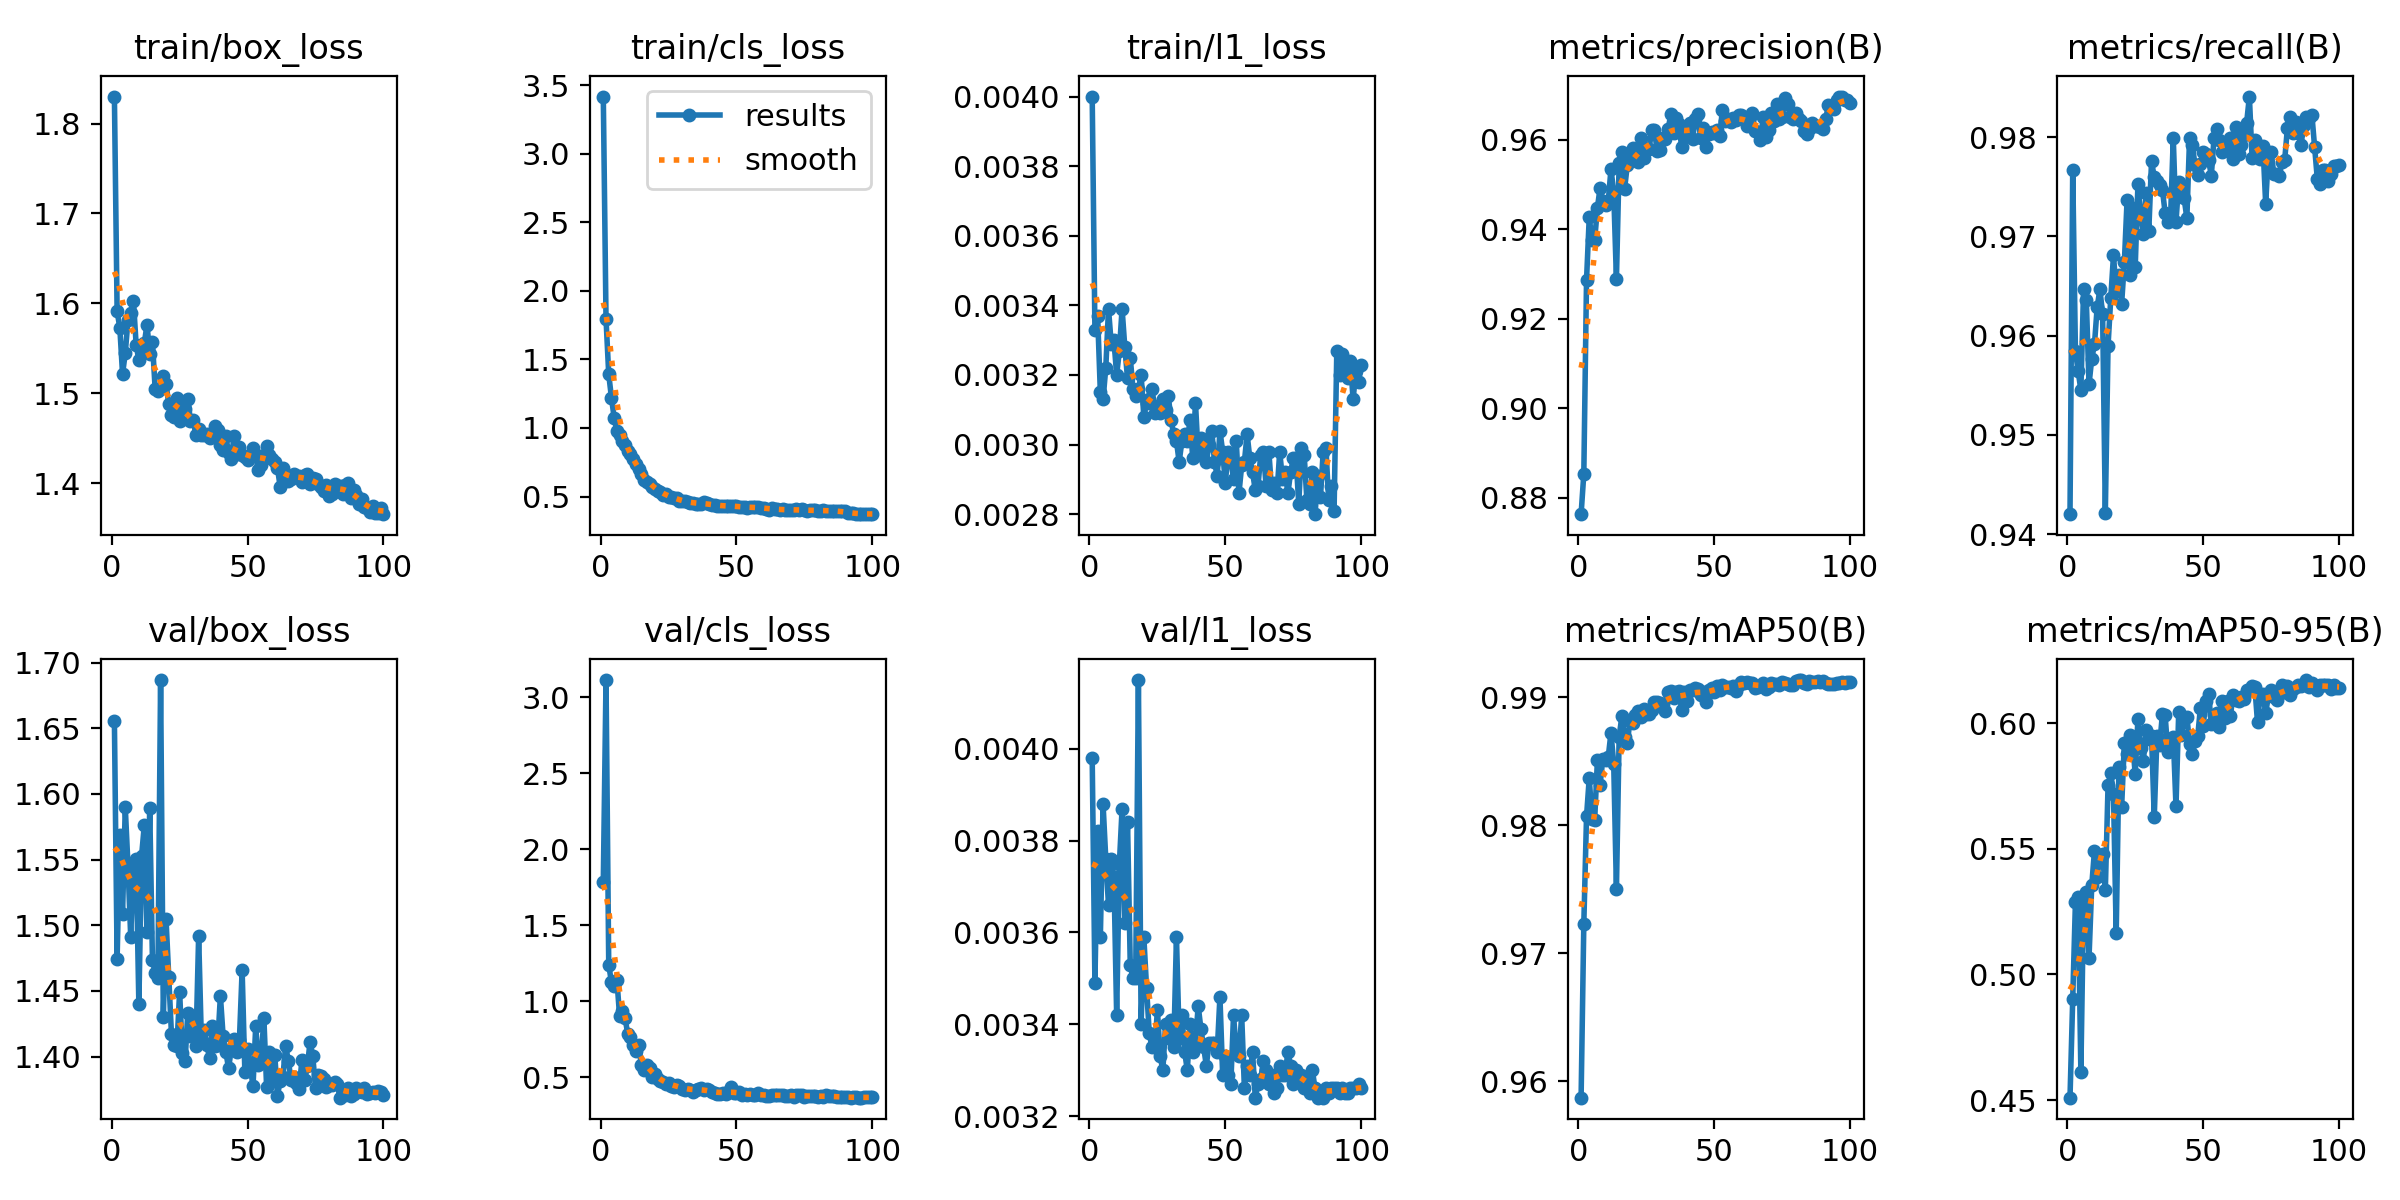

In [36]:
from IPython.display import Image, display

dev_plot_path = f"/content/runs/detect/cell_detection/yolo26/yolo26_cell_train_{timestamp}/results.png"
display(Image(filename=dev_plot_path))

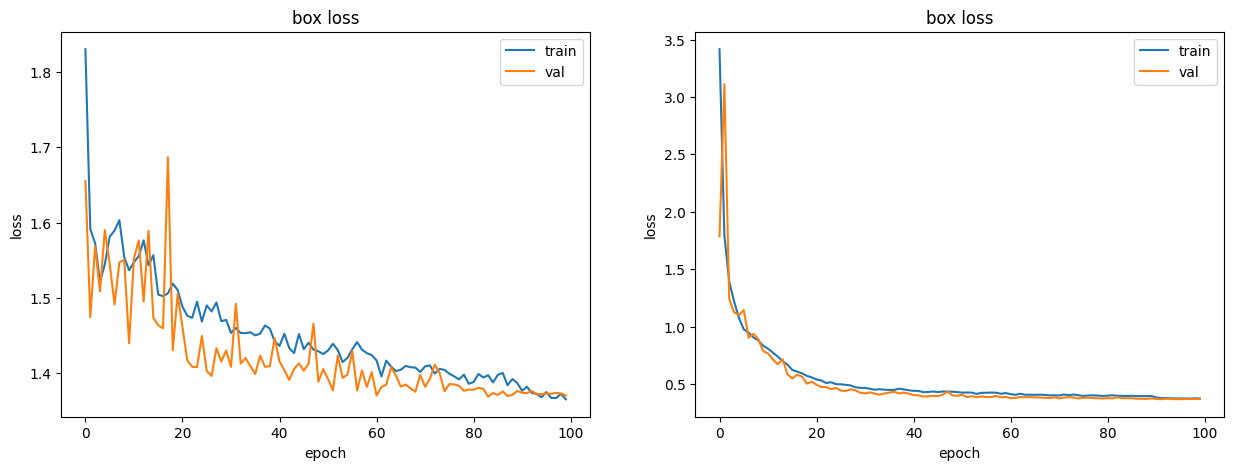

In [37]:
results_csv = pd.read_csv(f"/content/runs/detect/cell_detection/yolo26/yolo26_cell_train_{timestamp}/results.csv")
results_csv.head()

#plot 1
plt.subplots(nrows = 1, ncols = 2, figsize=(15,5))
plt.subplot(1,2,1)
plt.plot(results_csv["train/box_loss"])
plt.plot(results_csv["val/box_loss"])
plt.ylabel("loss")
plt.xlabel("epoch")
plt.legend(["train", "val"])
plt.title("box loss")

#plot 2
plt.subplot(1,2,2)
plt.plot(results_csv["train/cls_loss"])
plt.plot(results_csv["val/cls_loss"])
plt.ylabel("loss")
plt.xlabel("epoch")
plt.legend(["train", "val"])
plt.title("box loss")

plt.show()

In [38]:
metrics = model.val(data=f"{cell_yolo_dataset.location}/data.yaml")
print(f"precision {metrics.box.mp:.3f}  recall {metrics.box.mr:.3f}")
print(f"mAP50 {metrics.box.map50:.3f}  mAP50-95 {metrics.box.map:.3f}")

Ultralytics 8.4.198 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1255.4±391.5 MB/s, size: 39.8 KB)
val: Scanning /content/cell_detection/yolo26/valid/labels... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 1.4Kit/s 0.1s
val: New cache created: /content/cell_detection/yolo26/valid/labels.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.2s/it 8.1s
                   all        100       5574      0.963      0.982      0.991      0.617
Speed: 3.6ms preprocess, 7.4ms inference, 0.0ms loss, 30.8ms postprocess per image
Results saved to /content/runs/detect/cell_detection/yolo26/yolo26_cell_train_1793625139.6270702/runs/detect/val
precision 0.963  recall 0.982
mAP50 0.991  mAP50-95 0.6

### Blood Cell Detection

In [ ]:
from types import new_class
blood_project = rf.workspace(workspace_slug).project(blood_slug)  # *-------- Need to change this to specific dir --------*

new_version_id = blood_project.generate_version(settings={
    "preprocessing": {
        "auto-orient": True,
        "resize": {
            "width": 640,
            "height": 640,
            "format": "Fit within"
        }
    },
    "augmentation": {}  # Leave empty if you don't want to augment images
})

version = blood_project.version(3) #version generated on roboflow universe
blood_yolo_dataset = version.download(
                                model_format="yolo26",
                                location = f"./blood_detection/yolo26/{new_version_id}",
                                overwrite=True) #chose this format for PyTorch compatibality

loading Roboflow workspace...
loading Roboflow project...
Dataset version generation initialized for new version 13.



Extracting Dataset Version Zip to ./blood_detection/yolo26/13 in yolo26:: 100%|██████████| 1752/1752 [00:00<00:00, 8951.40it/s]


In [ ]:
blood_yolo_dataset.location

'/content/blood_detection/yolo26/13'

In [ ]:
#Evaluate YOLO26 model trained on our cell data on blood cell model

metrics = model.val(data=f"{blood_yolo_dataset.location}/data.yaml",
                    split = "test",
                    plots = True,
                    project = "./blood_detection/yolo26",
                    name = f"yolo26_cell_train_{timestamp}")

print(f"precision {metrics.box.mp:.3f}  recall {metrics.box.mr:.3f}")
print(f"mAP50 {metrics.box.map50:.3f}  mAP50-95 {metrics.box.map:.3f}")

Ultralytics 8.4.192 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 737.2±192.0 MB/s, size: 23.0 KB)
val: Scanning /content/blood_detection/yolo26/13/test/labels... 36 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 36/36 1.8Kit/s 0.0s
val: New cache created: /content/blood_detection/yolo26/13/test/labels.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.7it/s 1.8s
                   all         36        471     0.0605      0.119     0.0306    0.00976
Speed: 10.3ms preprocess, 6.6ms inference, 0.0ms loss, 11.8ms postprocess per image
Results saved to /content/runs/detect/blood_detection/yolo26/yolo26_cell_train_1793278266.8451254
precision 0.061  recall 0.119
mAP50 0.031  mAP50-95 0.010



0: 640x640 4 items, 5.3ms
1: 640x640 7 items, 5.3ms
2: 640x640 4 items, 5.3ms
3: 640x640 7 items, 5.3ms
4: 640x640 10 items, 5.3ms
Speed: 0.9ms preprocess, 5.3ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)


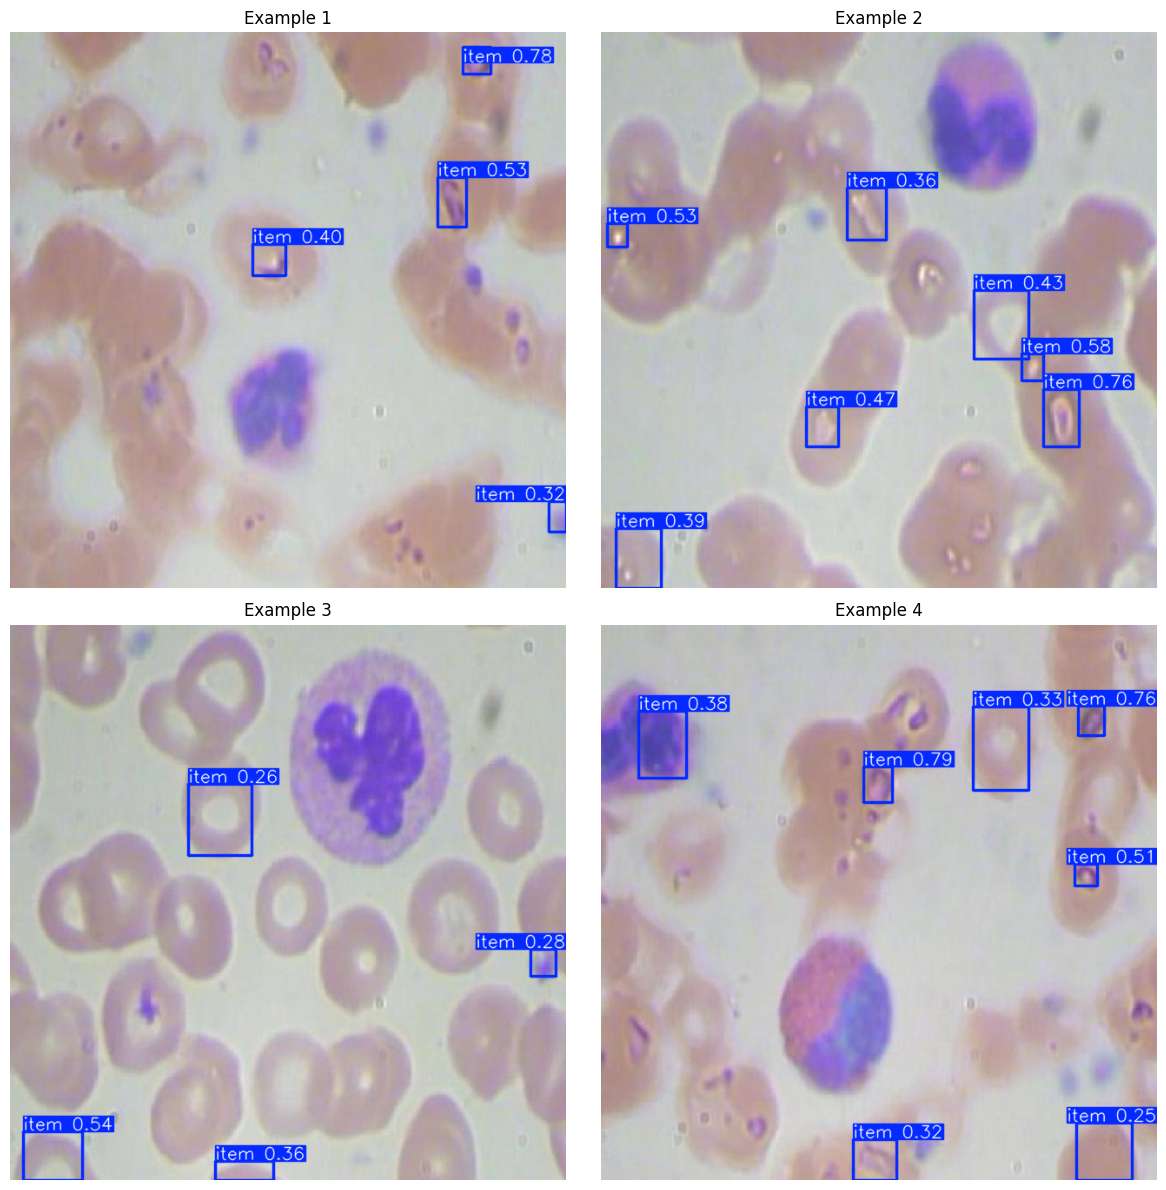

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Get a list of test images to run prediction on
test_images_dir = Path(blood_yolo_dataset.location) / "test" / "images"
test_image_files = list(test_images_dir.glob("*.jpg"))[:5]  # Get up to 5 images

# 2. Run prediction using your trained model
prediction_results = model(test_image_files)

# 3. Select how many images you want to display in your grid
num_examples = min(len(prediction_results), 4)  # Use 4 to fit perfectly in a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(12, 12))  # Creates a 2x2 grid layout
axes = axes.ravel()  # Flattens the grid matrix into a simple list for looping

for i in range(4):
    if i < len(prediction_results):
        result = prediction_results[i]
        # .plot() returns a standard BGR numpy array with your targets drawn on top
        plotted_bgr = result.plot()

        # Convert BGR array (OpenCV style) to RGB array (Matplotlib style)
        plotted_rgb = plotted_bgr[:, :, ::-1]

        # Render the image inside its respective grid cell slot
        axes[i].imshow(plotted_rgb)
        axes[i].axis("off")  # Hides graph axis coordinates
        axes[i].set_title(f"Example {i+1}")
    else:
        axes[i].axis("off")  # Hide unused subplots if fewer than 4 examples

plt.tight_layout()
plt.show()

In [ ]:
%ls runs/detect/cell_detection/yolo26/yolo26_cell_train_1793277086.2397363/weights

best.pt  last.pt


In [ ]:
best_model = Path(f"./runs/detect/cell_detection/yolo26/yolo26_cell_train_{timestamp}/weights/best.pt")
model = YOLO(best_model)


NameError: name 'Path' is not defined

### tomato detection

In [62]:
tomato_slug = userdata.get('ROBOFLOW_PROJECT_TOMATO')
tomato_project = rf.workspace(workspace_slug).project(tomato_slug)  # *-------- Need to change this to specific dir --------*
new_version_id = tomato_project.generate_version(settings={
    "preprocessing": {
        "auto-orient": True,
        "resize": {
            "width": 640,
            "height": 640,
            "format": "Fill (with center crop) in"
        }
    },
    "augmentation": {}  # Leave empty if you don't want to augment images
})

version = tomato_project.version(new_version_id) #version generated on roboflow universe
tomato_yolo_dataset = version.download(
                                model_format="yolo26",
                                location = "./tomato_detection/yolo26",
                                overwrite=True) #chose this format for PyTorch compatibality


loading Roboflow workspace...
loading Roboflow project...
Dataset version generation initialized for new version 5.
Generating version still in progress. Progress: 0.0%
Exporting format yolo26 in progress : 95.0%
Version export complete for yolo26 format



Extracting Dataset Version Zip to ./tomato_detection/yolo26 in yolo26:: 100%|██████████| 303/303 [00:00<00:00, 5056.43it/s]


In [63]:
%cd ./tomato_detection/yolo26
%ls test/labels

/content/runs/detect/cell_detection/yolo26/yolo26_cell_train_1793625139.6270702/weights/tomato_detection/yolo26/tomato_detection/yolo26
tomato100_jpg.rf.e2748a6b37c53521a48979aa3fc48f6a.txt
tomato104_jpg.rf.b71b90913e947c1a2a0dd6507f6ae317.txt
tomato105_jpg.rf.d8183a0ce42efdb753eb4de30b4225b0.txt
tomato109_jpg.rf.90cc0c1be4ccc919d3c5d322c8a25033.txt
tomato110_jpg.rf.5aa36d71dd80acb50f9dff84bea22989.txt
tomato112_jpg.rf.430293cb7ff0d68e97a6b51d71d94752.txt
tomato118_jpg.rf.aef7362d4b8124a2a7eca7228172665b.txt
tomato124_jpg.rf.9d84817e2e9a53d0d3a0092f22d62b86.txt
tomato127_jpg.rf.c5caa430c80dc9792259a956c1fc682e.txt
tomato128_jpg.rf.f20fde7009402ddfbd74fc9f8255c9fc.txt
tomato131_jpg.rf.5e7cc20aaa044a3e40ff0e6d8b3065ef.txt
tomato132_jpg.rf.0865e6c10faf651d06ffbe32f4193fe9.txt
tomato138_jpg.rf.f64da496f36da9efa9913cff3a96dad3.txt
tomato140_jpg.rf.67ba45bf3ae9c12b7b2ef9da89fe7714.txt
tomato141_jpg.rf.c06b04fea4f9097d80a8de71353fb059.txt
tomato146_jpg.rf.04182232509726afcf557dd41e762934.txt


In [64]:
#Evaluate YOLO26 model trained on our cell data on blood cell model

metrics = model.val(data=f"{tomato_yolo_dataset.location}/data.yaml",
                    split = "test",
                    plots = True,
                    project = "./tomato_detection/yolo26",
                    name = f"yolo26_cell_train_{timestamp}")

print(f"precision {metrics.box.mp:.3f}  recall {metrics.box.mr:.3f}")
print(f"mAP50 {metrics.box.map50:.3f}  mAP50-95 {metrics.box.map:.3f}")

Ultralytics 8.4.198 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1045.9±319.4 MB/s, size: 42.4 KB)
val: Scanning /content/runs/detect/cell_detection/yolo26/yolo26_cell_train_1793625139.6270702/weights/tomato_detection/yolo26/tomato_detection/yolo26/test/labels... 45 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 45/45 2.1Kit/s 0.0s
val: New cache created: /content/runs/detect/cell_detection/yolo26/yolo26_cell_train_1793625139.6270702/weights/tomato_detection/yolo26/tomato_detection/yolo26/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.2it/s 2.5s
                   all         45        246     0.0193     0.0569    0.00204   0.000451
Speed: 9.9ms preprocess, 17.6ms inference, 0.1ms loss, 11.6ms postprocess per image
Results saved to /content/runs/de


0: 640x640 11 items, 5.2ms
1: 640x640 27 items, 5.2ms
2: 640x640 24 items, 5.2ms
3: 640x640 13 items, 5.2ms
4: 640x640 17 items, 5.2ms
Speed: 1.2ms preprocess, 5.2ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)


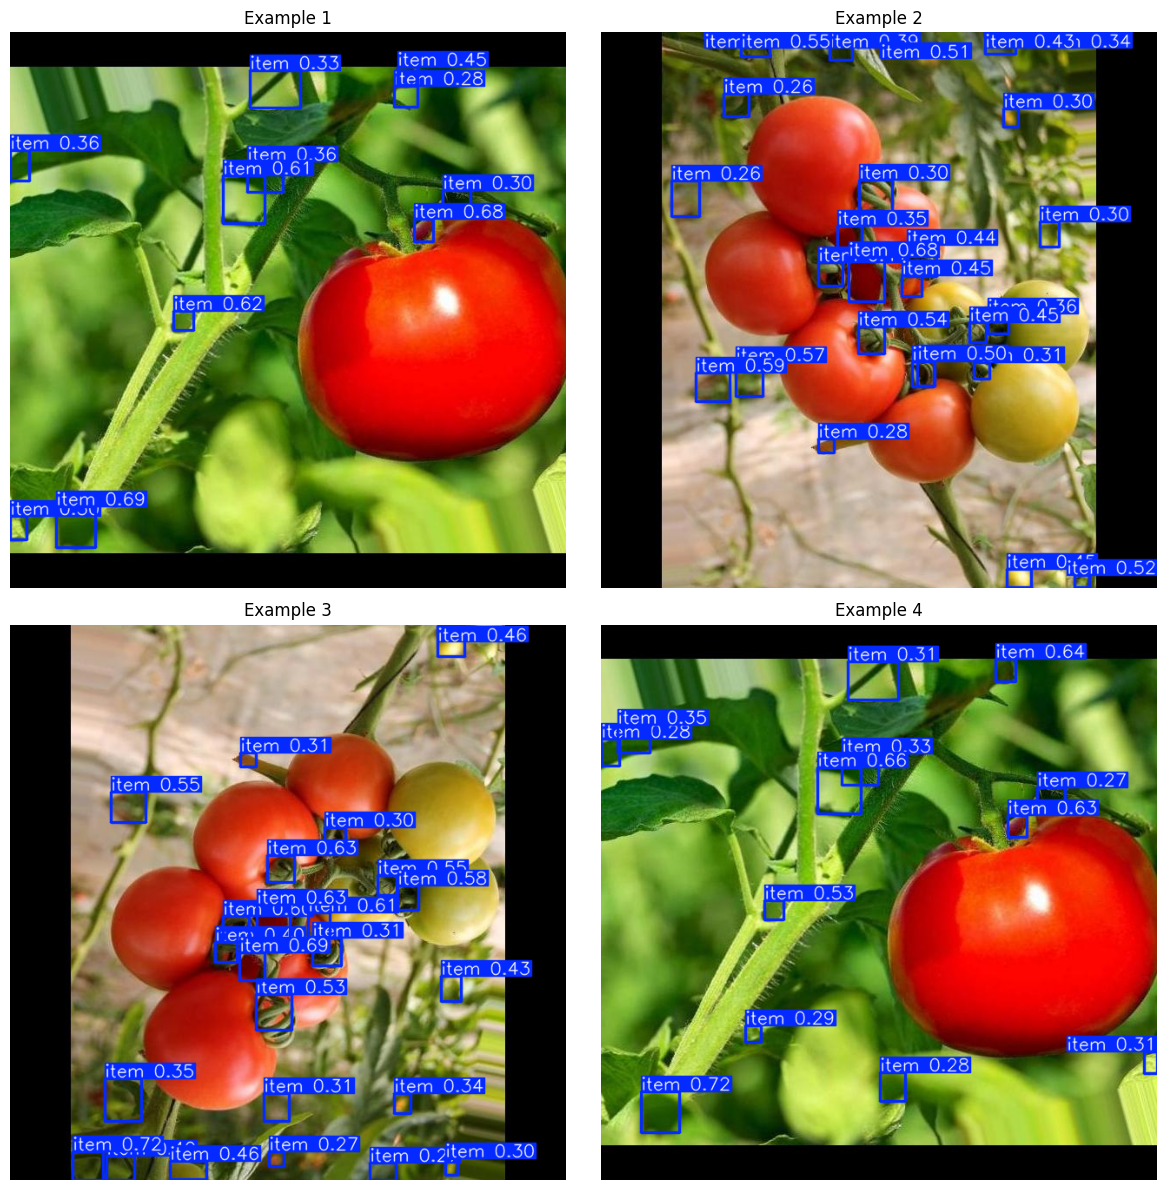

In [65]:
# 1. Get a list of test images to run prediction on
test_images_dir = Path(tomato_yolo_dataset.location) / "test" / "images"
test_image_files = list(test_images_dir.glob("*.jpg"))[:5]  # Get up to 5 images

# 2. Run prediction using your trained model
prediction_results = model(test_image_files)

# 3. Select how many images you want to display in your grid
num_examples = min(len(prediction_results), 4)  # Use 4 to fit perfectly in a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(12, 12))  # Creates a 2x2 grid layout
axes = axes.ravel()  # Flattens the grid matrix into a simple list for looping

for i in range(4):
    if i < len(prediction_results):
        result = prediction_results[i]
        # .plot() returns a standard BGR numpy array with your targets drawn on top
        plotted_bgr = result.plot()

        # Convert BGR array (OpenCV style) to RGB array (Matplotlib style)
        plotted_rgb = plotted_bgr[:, :, ::-1]

        # Render the image inside its respective grid cell slot
        axes[i].imshow(plotted_rgb)
        axes[i].axis("off")  # Hides graph axis coordinates
        axes[i].set_title(f"Example {i+1}")
    else:
        axes[i].axis("off")  # Hide unused subplots if fewer than 4 examples

plt.tight_layout()
plt.show()

### Detecting Eggs

In [71]:
egg_slug = userdata.get('ROBOFLOW_PROJECT_EGG')
egg_project = rf.workspace(workspace_slug).project(egg_slug)  # *-------- Need to change this to specific dir --------*
new_version_id = egg_project.generate_version(settings={
    "preprocessing": {
        "auto-orient": True,
        "resize": {
            "width": 640,
            "height": 640,
            "format": "Fill (with center crop) in"
        }
    },
    "augmentation": {}  # Leave empty if you don't want to augment images
})

version = egg_project.version(new_version_id) #version generated on roboflow universe
egg_yolo_dataset = version.download(
                                model_format="yolo26",
                                location = "./egg_detection/yolo26",
                                overwrite=True) #chose this format for PyTorch compatibality


loading Roboflow workspace...
loading Roboflow project...
Dataset version generation initialized for new version 3.
Generating version still in progress. Progress: 0.0%
Exporting format yolo26 in progress : 0.1%
Version export complete for yolo26 format



Extracting Dataset Version Zip to ./egg_detection/yolo26 in yolo26:: 100%|██████████| 110/110 [00:00<00:00, 4767.98it/s]


In [74]:
#Evaluate YOLO26 model trained on our cell data on blood cell model

metrics = model.val(data=f"{egg_yolo_dataset.location}/data.yaml",
                    split = "test",
                    plots = True,
                    project = "./egg_detection/yolo26",
                    name = f"yolo26_cell_train_{timestamp}")

print(f"precision {metrics.box.mp:.3f}  recall {metrics.box.mr:.3f}")
print(f"mAP50 {metrics.box.map50:.3f}  mAP50-95 {metrics.box.map:.3f}")

Ultralytics 8.4.198 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1297.6±441.7 MB/s, size: 34.4 KB)
val: Scanning /content/runs/detect/cell_detection/yolo26/yolo26_cell_train_1793625139.6270702/weights/tomato_detection/yolo26/tomato_detection/yolo26/egg_detection/yolo26/test/labels.cache... 140 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 140/140 41.9Mit/s 0.0s
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.4it/s 3.7s
                   all        140        757     0.0129     0.0396    0.00114   0.000243
Speed: 3.4ms preprocess, 4.0ms inference, 0.0ms loss, 3.5ms postprocess per image
Results saved to /content/runs/detect/cell_detection/yolo26/yolo26_cell_train_1793625139.6270702/weights/tomato


0: 640x640 11 items, 5.2ms
1: 640x640 7 items, 5.2ms
2: 640x640 26 items, 5.2ms
3: 640x640 27 items, 5.2ms
4: 640x640 31 items, 5.2ms
Speed: 1.0ms preprocess, 5.2ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)


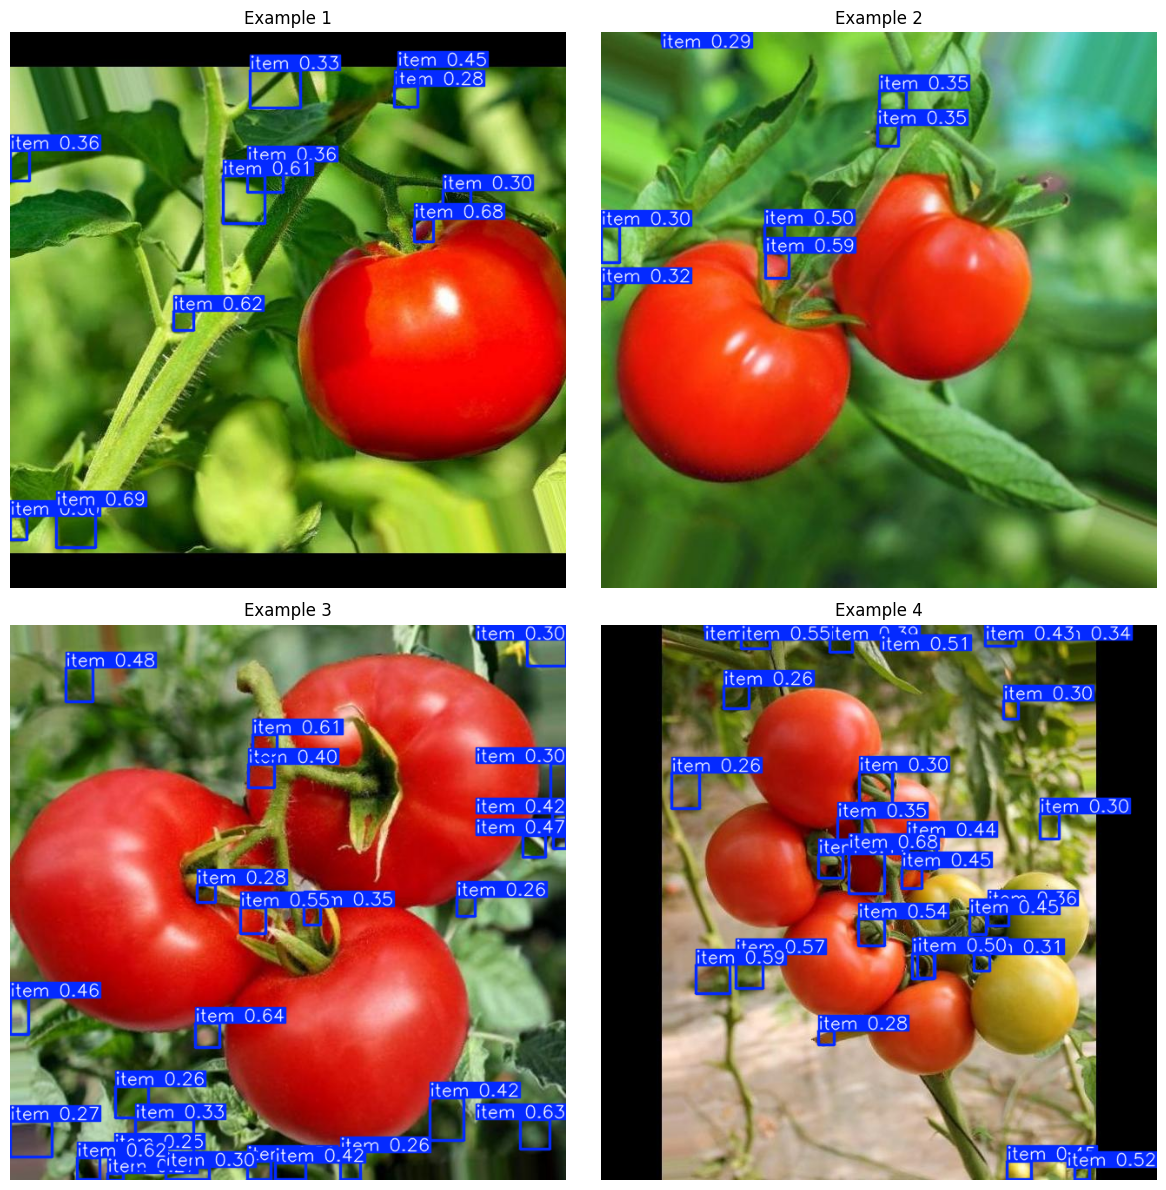

In [76]:
# 1. Get a list of test images to run prediction on
test_images_dir = Path(egg_yolo_dataset.location) / "test" / "images"
test_image_files = list(test_images_dir.glob("*.jpg"))[:5]  # Get up to 5 images

# 2. Run prediction using your trained model
prediction_results = model(test_image_files)

# 3. Select how many images you want to display in your grid
num_examples = min(len(prediction_results), 4)  # Use 4 to fit perfectly in a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(12, 12))  # Creates a 2x2 grid layout
axes = axes.ravel()  # Flattens the grid matrix into a simple list for looping

for i in range(4):
    if i < len(prediction_results):
        result = prediction_results[i]
        # .plot() returns a standard BGR numpy array with your targets drawn on top
        plotted_bgr = result.plot()

        # Convert BGR array (OpenCV style) to RGB array (Matplotlib style)
        plotted_rgb = plotted_bgr[:, :, ::-1]

        # Render the image inside its respective grid cell slot
        axes[i].imshow(plotted_rgb)
        axes[i].axis("off")  # Hides graph axis coordinates
        axes[i].set_title(f"Example {i+1}")
    else:
        axes[i].axis("off")  # Hide unused subplots if fewer than 4 examples

plt.tight_layout()
plt.show()